In [ ]:
# Adam Lee
# COMP5600 - Assignment 2, Optimization
# 10/2/2026

#imports

import random
import math
import time
import matplotlib.pyplot as plt

In [ ]:
#Part 1 - state representation

import random

def random_state(code_length):
    state = []

    for i in range(code_length):
        digit = random.randint(0, 9)
        state.append(digit)

    return state

#test cases
#print(random_state(4))
#print(random_state(6))
#print(random_state(8))

In [ ]:
#Part 2 - Evaluating a Guess

def evaluate_guess(candidate, guess):
    exact = 0
    misplaced = 0

    candidate_remaining = []
    guess_remaining = []

    for i in range(len(candidate)):
        if candidate[i] == guess[i]:
            exact += 1
        else:
            candidate_remaining.append(candidate[i])
            guess_remaining.append(guess[i])

    for digit in guess_remaining:
        if digit in candidate_remaining:
            misplaced += 1
            candidate_remaining.remove(digit)

    return exact, misplaced

#test cases
#candidate = [1, 1, 2, 3]
#guess = [1, 2, 1, 4]

#print(evaluate_guess(candidate, guess))



In [ ]:
#part 3 - objective function
def cost(candidate, clues):
    total_cost = 0

    for guess, expected_exact, expected_misplaced in clues:
        actual_exact, actual_misplaced = evaluate_guess(candidate, guess)

        total_cost += abs(expected_exact - actual_exact)
        total_cost += abs(expected_misplaced - actual_misplaced)

    return total_cost

#test case
#secret = [4, 1, 7, 3]

#clues = [
 #   ([4, 7, 5, 1], 1, 2),
 #   ([4, 1, 7, 3], 4, 0),
  #  ([5, 5, 5, 5], 0, 0)
#]

#print("Secret cost:", cost(secret, clues))

In [ ]:
#part 4 - neighbor function

def get_neighbors(state):
    neighbors = []

    for i in range(len(state)):
        for digit in range(10):
            if digit != state[i]:
                neighbor = state.copy()
                neighbor[i] = digit
                neighbors.append(neighbor)

    return neighbors


def random_neighbor(state):
    neighbor = state.copy()

    position = random.randrange(len(state))
    new_digit = random.randint(0, 9)

    while new_digit == state[position]:
        new_digit = random.randint(0, 9)

    neighbor[position] = new_digit

    return neighbor

#test case
#state = [4, 1, 7, 3]

#neighbors = get_neighbors(state)

#print("Original State:", state)
#print("Number of Neighbors:", len(neighbors))
#print("Random Neighbor:", random_neighbor(state))

In [ ]:
#Part 5 - Hill climbing

def hill_climb(clues, code_length, max_steps):
    current = random_state(code_length)
    current_cost = cost(current, clues)

    iterations = 0

    while iterations < max_steps:
        # Stop if we found a valid solution
        if current_cost == 0:
            break

        # Generate all neighbors
        neighbors = get_neighbors(current)

        # Find the neighbor with the lowest cost
        best_neighbor = current
        best_cost = current_cost

        for neighbor in neighbors:
            neighbor_cost = cost(neighbor, clues)

            if neighbor_cost < best_cost:
                best_neighbor = neighbor
                best_cost = neighbor_cost

        # Stop if no neighbor improves the current state
        if best_cost >= current_cost:
            break

        # Move to the best neighbor
        current = best_neighbor
        current_cost = best_cost

        iterations += 1

    return current, current_cost, iterations


# test case

#clues = [
 #   ([4, 7, 5, 1], 1, 2),
 #  ([4, 1, 7, 3], 4, 0),
#    ([5, 5, 5, 5], 0, 0)
#]

#solution, final_cost, iterations = hill_climb(
 #   clues,
  #  code_length=4,
   # max_steps=100
#)

#print("Final State:", solution)
#print("Final Cost:", final_cost)
#print("Iterations:", iterations)

In [ ]:
#Part 6 - Simulated Annealing

def simulated_annealing(clues, code_length, max_steps,
                        initial_temperature, cooling_rate):

    current = random_state(code_length)
    current_cost = cost(current, clues)

    temperature = initial_temperature
    iterations = 0

    while iterations < max_steps and temperature > 0.0001:

        # stop if we found a valid solution
        if current_cost == 0:
            break

        # generate one random neighbor
        neighbor = random_neighbor(current)
        neighbor_cost = cost(neighbor, clues)

        # calculate change in cost
        delta = neighbor_cost - current_cost

        # always accept an improvement
        if delta < 0:
            current = neighbor
            current_cost = neighbor_cost

        # sometimes accept an equal or worse state
        else:
            probability = math.exp(-delta / temperature)

            if random.random() < probability:
                current = neighbor
                current_cost = neighbor_cost

        # cool the temperature
        temperature = cooling_rate * temperature

        iterations += 1

    return current, current_cost, iterations

    # test case
#    solution, final_cost, iterations = simulated_annealing(
#    clues,
#    code_length=4,
#    max_steps=10000,
#    initial_temperature=10.0,
#    cooling_rate=0.995
#)

#print("Final State:", solution)
#print("Final Cost:", final_cost)
#print("Iterations:", iterations)

In [ ]:
# Part 7 - Generate Codebreaker Problems

def generate_problem(code_length, num_clues):
    # generate the secret code
    secret_code = random_state(code_length)

    clues = []

    # generate random guesses
    for i in range(num_clues):
        guess = random_state(code_length)

        # get the correct feedback using the secret code
        exact, misplaced = evaluate_guess(secret_code, guess)

        # store the guess and its feedback
        clues.append((guess, exact, misplaced))

    return secret_code, clues


# test case
# secret_code, clues = generate_problem(
#     code_length=4,
#     num_clues=10
# )

# print("Secret Code:", secret_code)
# print("Secret Cost:", cost(secret_code, clues))

# print("\nClues:")

# for guess, exact, misplaced in clues:
#     print(
#         "Guess:", guess,
#         "Exact:", exact,
#         "Misplaced:", misplaced
#     )

In [ ]:
#Part 8 - Optimizing Experiments

def run_experiments(code_length, num_clues=10, runs=10):
    hill_results = []
    annealing_results = []

    for run in range(runs):

        # generates one problem for both algorithms
        secret_code, clues = generate_problem(code_length, num_clues)


        # Hill Climbing

        start_time = time.perf_counter()

        hill_solution, hill_cost, hill_iterations = hill_climb(
            clues,
            code_length,
            max_steps=1000
        )

        end_time = time.perf_counter()
        hill_runtime = end_time - start_time

        hill_results.append({
            "secret": secret_code,
            "solution": hill_solution,
            "cost": hill_cost,
            "iterations": hill_iterations,
            "runtime": hill_runtime
        })


        # Simulated Annealing

        start_time = time.perf_counter()

        sa_solution, sa_cost, sa_iterations = simulated_annealing(
            clues,
            code_length,
            max_steps=10000,
            initial_temperature=10.0,
            cooling_rate=0.995
        )

        end_time = time.perf_counter()
        sa_runtime = end_time - start_time

        annealing_results.append({
            "secret": secret_code,
            "solution": sa_solution,
            "cost": sa_cost,
            "iterations": sa_iterations,
            "runtime": sa_runtime
        })

    return hill_results, annealing_results

In [ ]:
# summarizes results and gets results for table

def summarize_results(results):
    successful_runs = 0
    total_cost = 0
    total_iterations = 0
    total_runtime = 0

    for result in results:

        if result["cost"] == 0:
            successful_runs += 1

        total_cost += result["cost"]
        total_iterations += result["iterations"]
        total_runtime += result["runtime"]

    runs = len(results)

    success_rate = successful_runs / runs
    avg_cost = total_cost / runs
    avg_iterations = total_iterations / runs
    avg_runtime = total_runtime / runs

    return (
        successful_runs,
        success_rate,
        avg_cost,
        avg_iterations,
        avg_runtime
    )

In [ ]:
#runs all three problem sizes

hill_4, sa_4 = run_experiments(4)
hill_6, sa_6 = run_experiments(6)
hill_8, sa_8 = run_experiments(8)

In [ ]:
# print individual experiment results

for code_length, hill_data, sa_data in [
    (4, hill_4, sa_4),
    (6, hill_6, sa_6),
    (8, hill_8, sa_8)
]:
    print("\nCode Length:", code_length)

    for i in range(10):
        print("\nRun", i + 1)
        print("Secret Code:", hill_data[i]["secret"])

        print("Hill Climbing:")
        print("Found Code:", hill_data[i]["solution"])
        print("Final Cost:", hill_data[i]["cost"])
        print("Iterations:", hill_data[i]["iterations"])
        print("Runtime:", hill_data[i]["runtime"])

        print("Simulated Annealing:")
        print("Found Code:", sa_data[i]["solution"])
        print("Final Cost:", sa_data[i]["cost"])
        print("Iterations:", sa_data[i]["iterations"])
        print("Runtime:", sa_data[i]["runtime"])


Code Length: 4

Run 1
Secret Code: [2, 2, 0, 2]
Hill Climbing:
Found Code: [6, 4, 3, 4]
Final Cost: 3
Iterations: 3
Runtime: 0.002130159999978787
Simulated Annealing:
Found Code: [2, 2, 0, 2]
Final Cost: 0
Iterations: 395
Runtime: 0.005545559999973193

Run 2
Secret Code: [5, 1, 9, 1]
Hill Climbing:
Found Code: [7, 7, 8, 9]
Final Cost: 7
Iterations: 3
Runtime: 0.001652630000080535
Simulated Annealing:
Found Code: [5, 1, 9, 1]
Final Cost: 0
Iterations: 233
Runtime: 0.004526531000010436

Run 3
Secret Code: [9, 6, 0, 9]
Hill Climbing:
Found Code: [0, 0, 0, 5]
Final Cost: 5
Iterations: 1
Runtime: 0.0010646089999681863
Simulated Annealing:
Found Code: [9, 6, 0, 9]
Final Cost: 0
Iterations: 3
Runtime: 7.643999970241566e-05

Run 4
Secret Code: [8, 8, 2, 5]
Hill Climbing:
Found Code: [3, 4, 7, 3]
Final Cost: 8
Iterations: 1
Runtime: 0.0010206000001744542
Simulated Annealing:
Found Code: [5, 8, 8, 4]
Final Cost: 6
Iterations: 2297
Runtime: 0.0380622709999443

Run 5
Secret Code: [3, 4, 0, 4]
Hil

In [ ]:
#prints results

results = [
    (4, "Hill Climbing", hill_4),
    (4, "Simulated Annealing", sa_4),
    (6, "Hill Climbing", hill_6),
    (6, "Simulated Annealing", sa_6),
    (8, "Hill Climbing", hill_8),
    (8, "Simulated Annealing", sa_8)
]

print(
    f"{'Code Length':<12}"
    f"{'Algorithm':<22}"
    f"{'Successful':<12}"
    f"{'Success Rate':<14}"
    f"{'Avg Cost':<12}"
    f"{'Avg Iter':<12}"
    f"{'Avg Runtime':<15}"
)

for code_length, algorithm, data in results:

    successful, rate, avg_cost, avg_iter, avg_runtime = summarize_results(data)

    print(
        f"{code_length:<12}"
        f"{algorithm:<22}"
        f"{successful:<12}"
        f"{rate:<14.2f}"
        f"{avg_cost:<12.2f}"
        f"{avg_iter:<12.2f}"
        f"{avg_runtime:<15.6f}"
    )

Code Length Algorithm             Successful  Success Rate  Avg Cost    Avg Iter    Avg Runtime    
4           Hill Climbing         2           0.20          3.50        2.50        0.001591       
4           Simulated Annealing   8           0.80          0.80        747.50      0.011914       
6           Hill Climbing         0           0.00          6.30        3.60        0.004842       
6           Simulated Annealing   2           0.20          2.80        1977.60     0.043189       
8           Hill Climbing         1           0.10          5.50        5.00        0.013466       
8           Simulated Annealing   2           0.20          3.70        2011.80     0.075701       


In [ ]:
# Part 9 - Visual Optimization Process
# Hill Climbing with cost history

def hill_climb_history(clues, code_length, max_steps):
    # set up the initial state and values
    current = random_state(code_length)
    current_cost = cost(current, clues)

    iterations = 0
    cost_history = [current_cost]

    while iterations < max_steps:
        if current_cost == 0:
            break

        # generate all neighbors
        neighbors = get_neighbors(current)

        best_neighbor = current
        best_cost = current_cost

        # find the neighbor with the lowest cost
        for neighbor in neighbors:
            neighbor_cost = cost(neighbor, clues)

            if neighbor_cost < best_cost:
                best_neighbor = neighbor
                best_cost = neighbor_cost

        # stop if no neighbor improves the cost
        if best_cost >= current_cost:
            break

        # move to the best neighbor and record the cost
        current = best_neighbor
        current_cost = best_cost

        iterations += 1
        cost_history.append(current_cost)

    return current, current_cost, iterations, cost_history

In [ ]:
# Simulated Annealing with cost history

def simulated_annealing_history(clues, code_length, max_steps,
                                initial_temperature, cooling_rate):

    # set up the initial state and values
    current = random_state(code_length)
    current_cost = cost(current, clues)

    temperature = initial_temperature
    iterations = 0
    cost_history = [current_cost]

    while iterations < max_steps and temperature > 0.0001:
        if current_cost == 0:
            break

        # generate and evaluate a random neighbor
        neighbor = random_neighbor(current)
        neighbor_cost = cost(neighbor, clues)

        delta = neighbor_cost - current_cost

        # accept better states or sometimes accept worse states
        if delta < 0:
            current = neighbor
            current_cost = neighbor_cost
        else:
            probability = math.exp(-delta / temperature)

            if random.random() < probability:
                current = neighbor
                current_cost = neighbor_cost

        # cool temperature and record cost
        temperature = cooling_rate * temperature
        iterations += 1
        cost_history.append(current_cost)

    return current, current_cost, iterations, cost_history

In [ ]:
# generates problem
secret_8, clues_8 = generate_problem(
    code_length=8,
    num_clues=10
)

print("Secret Code:", secret_8)

Secret Code: [9, 2, 8, 5, 4, 2, 1, 2]


In [ ]:
# runs both algorithms

hill_solution, hill_cost, hill_iterations, hill_history = hill_climb_history(
    clues_8,
    code_length=8,
    max_steps=1000
)

sa_solution, sa_cost, sa_iterations, sa_history = simulated_annealing_history(
    clues_8,
    code_length=8,
    max_steps=10000,
    initial_temperature=10.0,
    cooling_rate=0.995
)

# prints results
print("Secret Code:", secret_8)

print("\nHill Climbing")
print("Solution:", hill_solution)
print("Final Cost:", hill_cost)
print("Iterations:", hill_iterations)

print("\nSimulated Annealing")
print("Solution:", sa_solution)
print("Final Cost:", sa_cost)
print("Iterations:", sa_iterations)

Secret Code: [9, 2, 8, 5, 4, 2, 1, 2]

Hill Climbing
Solution: [2, 6, 2, 1, 4, 8, 2, 1]
Final Cost: 3
Iterations: 4

Simulated Annealing
Solution: [1, 5, 2, 4, 3, 8, 2, 2]
Final Cost: 5
Iterations: 2297


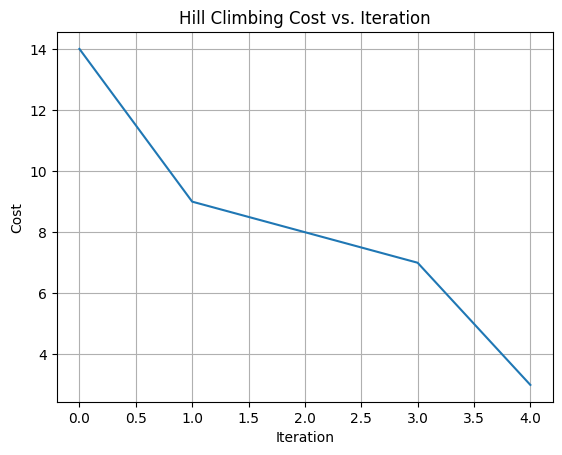

In [ ]:
# Hill Climbing plot

plt.figure()

plt.plot(range(len(hill_history)), hill_history)

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Hill Climbing Cost vs. Iteration")

plt.grid(True)
plt.show()

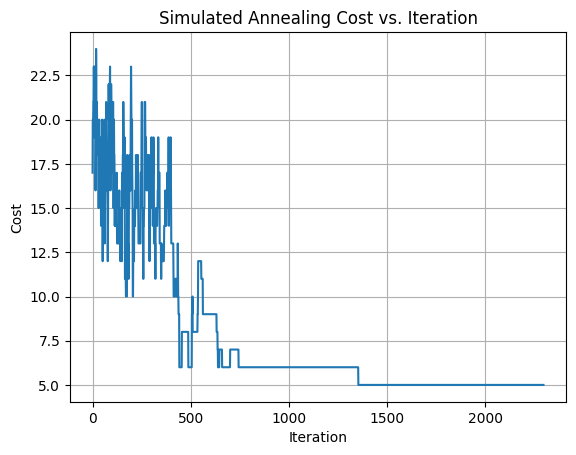

In [ ]:
# Simulated Annealing plot

plt.figure()

plt.plot(range(len(sa_history)), sa_history)

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Simulated Annealing Cost vs. Iteration")

plt.grid(True)
plt.show()

### 1. Why can the Codebreaker problem be represented as an optimization problem using the cost function defined earlier?

The Codebreaker problem can be treated as an optimization problem because the cost tells us how close a code is to matching all the clues. The goal is to keep lowering the cost until it reaches zero.

### 2. Why does a cost of zero indicate that a candidate satisfies the generated constraints?

A cost of zero means the candidate code matches all the feedback from the clues correctly. There are no differences between the expected exact and misplaced matches and what the candidate produces.

### 3. Is a zero-cost solution guaranteed to be identical to the original secret code? Explain why or why not.

No, a zero-cost solution does not have to be the same as the original secret code. There could be more than one code that matches all the clues, especially if the clues do not give enough information to narrow it down to only one code.

### 4. Hill Climbing may stop with a cost greater than zero even though a valid solution exists. Why can this happen?

Hill Climbing can get stuck at a local optimum because it only moves when a neighbor has a lower cost. If none of the nearby states are better, it stops even if a valid solution exists somewhere else.

### 5. Why does Simulated Annealing sometimes accept a neighboring state with a higher cost?

Simulated Annealing sometimes accepts a worse state to help it get out of a local optimum. This gives it a chance to explore other possible solutions instead of getting stuck in one area.

### 6. Compare the results for the 4-digit, 6-digit, and 8-digit problems. How did increasing the size of the state space affect the algorithms?

As the code increased from 4 digits to 6 and 8 digits, there were a lot more possible codes for the algorithms to search through. The larger problems generally made it harder for the algorithms to find a zero-cost solution and could require more searching.

### 7. Compare the success rates of Hill Climbing and Simulated Annealing. What characteristics of the algorithms help explain the difference you observed?

The success rates were different because the two algorithms search differently. Hill Climbing only moves to better states, so it can get stuck, while Simulated Annealing can sometimes move to a worse state and use that to get out of a local optimum.

### 8. What would happen if the temperature in Simulated Annealing decreased extremely quickly?

If the temperature dropped too quickly, Simulated Annealing would stop accepting worse states much sooner. This would make it act more like Hill Climbing and make it easier to get stuck at a local optimum.

### 9. What would happen if the temperature remained high for most of the search?

If the temperature stayed high, the algorithm would keep accepting worse states more often. This could help it explore more solutions, but it could also make it harder to settle on a good solution.

### 10. The neighborhood in this assignment changes exactly one digit. How might the behavior of the algorithms change if a neighboring state were allowed to modify two digits at once?

If two digits could change at once, the algorithms could make bigger moves through the possible solutions. This could help them get out of some local optima, but it would also create more possible neighbors to search through.